# Machine Learning with Linear Regression
## House Price Prediction: Price (€) vs. Living Area (m²)

**Learning Objectives:**
- Understand how linear regression works as the simplest ML model
- Generate, explore, and visualize a dataset
- Train a model, evaluate it with metrics (MSE, R²), and make predictions

In [1]:
# === IMPORTS ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Reproducibility
np.random.seed(42)

# Plot style
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')

print('Setup complete ✓')

Setup complete ✓


---
## 1. Generate Dataset (220 Houses)

In [2]:
# === DATASET: 220 houses ===
n = 220

# Living area: 25 m² (studio) to 200 m² (villa)
living_area = np.random.uniform(25, 200, n)

# Price model: base price + price per m² + noise
# Realistic: ~50,000 € base + ~2,800 €/m² ± variation
base_price = 50_000
price_per_m2 = 2_800
noise = np.random.normal(0, 25_000, n)  # ±25k € random variation

price = base_price + price_per_m2 * living_area + noise

# Create DataFrame
df = pd.DataFrame({
    'living_area_m2': np.round(living_area, 1),
    'price_eur': np.round(price, -2)  # round to nearest 100
})

# Prevent negative prices
df['price_eur'] = df['price_eur'].clip(lower=30_000)

print(f'Dataset: {len(df)} houses')
print(f'Living area: {df.living_area_m2.min():.0f} – {df.living_area_m2.max():.0f} m²')
print(f'Price:       {df.price_eur.min():,.0f} – {df.price_eur.max():,.0f} €')
df.head(10)

Dataset: 220 houses
Living area: 26 – 198 m²
Price:       106,200 – 661,900 €


,living_area_m2,price_eur
0,90.5,324100.0
1,191.4,633300.0
2,153.1,472500.0
3,129.8,394500.0
4,52.3,174200.0
5,52.3,176000.0
6,35.2,146500.0
7,176.6,553000.0
8,130.2,421500.0
9,148.9,487600.0


---
## 2. Exploratory Data Analysis

In [3]:
# === DESCRIPTIVE STATISTICS ===
print('=== Descriptive Statistics ===')
print(df.describe().round(1))
print(f'\nPearson Correlation: {df.corr().iloc[0,1]:.4f}')

=== Descriptive Statistics ===
       living_area_m2  price_eur
count           220.0      220.0
mean            109.1   357187.3
std              51.6   146700.6
min              25.9   106200.0
25%              64.5   221825.0
50%             111.8   351550.0
75%             152.8   479850.0
max             197.7   661900.0

Pearson Correlation: 0.9864


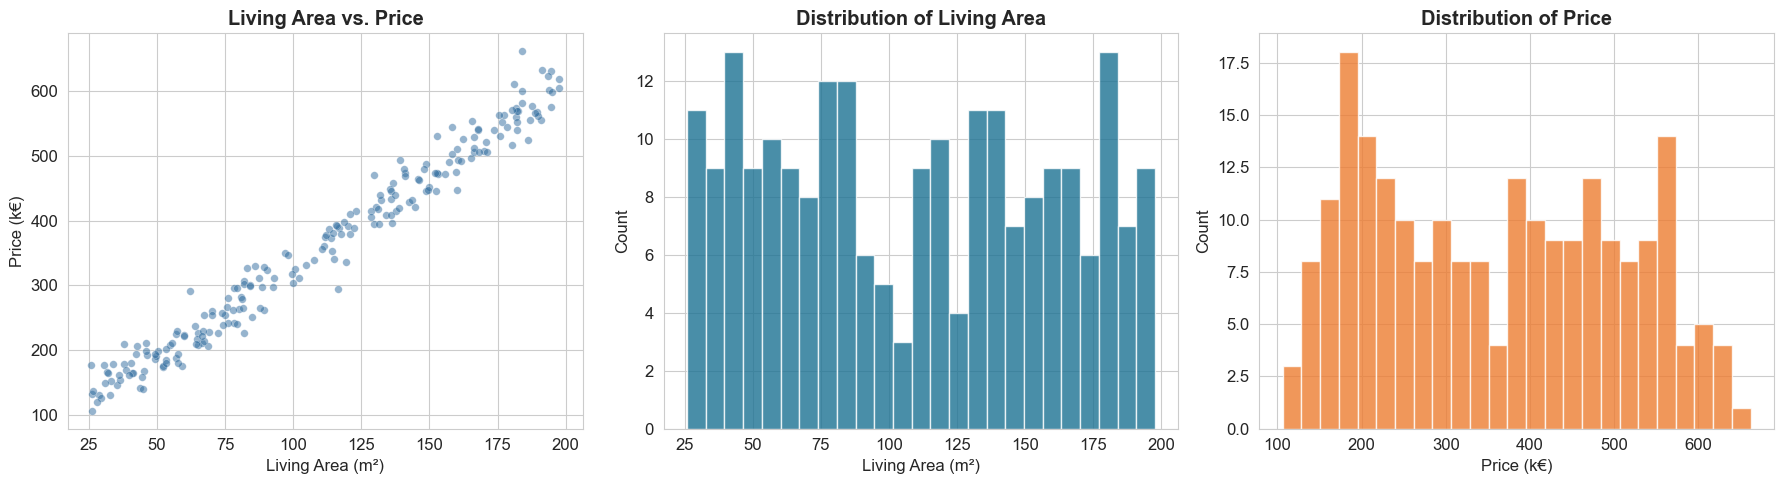

In [4]:
# === VISUALIZATION ===
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Scatter: Area vs. Price
axes[0].scatter(df['living_area_m2'], df['price_eur'] / 1000,
                alpha=0.5, s=30, color='#2E6B9E', edgecolor='white', linewidth=0.3)
axes[0].set_xlabel('Living Area (m²)')
axes[0].set_ylabel('Price (k€)')
axes[0].set_title('Living Area vs. Price', fontweight='bold')

# 2) Histogram: Area
axes[1].hist(df['living_area_m2'], bins=25, color='#1C7293',
             edgecolor='white', alpha=0.8)
axes[1].set_xlabel('Living Area (m²)')
axes[1].set_ylabel('Count')
axes[1].set_title('Distribution of Living Area', fontweight='bold')

# 3) Histogram: Price
axes[2].hist(df['price_eur'] / 1000, bins=25, color='#ED7D31',
             edgecolor='white', alpha=0.8)
axes[2].set_xlabel('Price (k€)')
axes[2].set_ylabel('Count')
axes[2].set_title('Distribution of Price', fontweight='bold')

plt.tight_layout()
plt.show()

---
## 3. Train / Test Split

In [5]:
# === FEATURES & TARGET ===
X = df[['living_area_m2']]   # Feature matrix (2D required by sklearn)
y = df['price_eur']           # Target vector (1D)

# 80% training, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Training set: {len(X_train)} houses ({len(X_train)/len(X)*100:.0f}%)')
print(f'Test set:     {len(X_test)} houses ({len(X_test)/len(X)*100:.0f}%)')

Training set: 176 houses (80%)
Test set:     44 houses (20%)


---
## 4. Train the Model

Linear model: **ŷ = w · x + b**

- `w` = weight (slope) = estimated price per m²
- `b` = bias (intercept) = base price

In [6]:
# === LINEAR REGRESSION ===
model = LinearRegression()
model.fit(X_train, y_train)

# Learned parameters
w = model.coef_[0]
b = model.intercept_

print('=== Learned Parameters ===')
print(f'Weight (w):          {w:,.1f} €/m²')
print(f'Bias (b):            {b:,.0f} €')
print(f'\nInterpretation:')
print(f'  Each additional m² increases the price by ~{w:,.0f} €')
print(f'  The base price (at 0 m²) would be ~{b:,.0f} €')
print(f'\nFormula: Price = {w:,.0f} · Area + {b:,.0f}')

=== Learned Parameters ===
Weight (w):          2,804.9 €/m²
Bias (b):            51,764 €

Interpretation:
  Each additional m² increases the price by ~2,805 €
  The base price (at 0 m²) would be ~51,764 €

Formula: Price = 2,805 · Area + 51,764


---
## 5. Predictions & Evaluation

In [7]:
# === PREDICTIONS ===
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

# === METRICS ===
metrics = pd.DataFrame({
    'Metric': ['MSE', 'RMSE', 'MAE', 'R²'],
    'Training': [
        f'{mean_squared_error(y_train, y_pred_train):,.0f}',
        f'{np.sqrt(mean_squared_error(y_train, y_pred_train)):,.0f} €',
        f'{mean_absolute_error(y_train, y_pred_train):,.0f} €',
        f'{r2_score(y_train, y_pred_train):.4f}',
    ],
    'Test': [
        f'{mean_squared_error(y_test, y_pred_test):,.0f}',
        f'{np.sqrt(mean_squared_error(y_test, y_pred_test)):,.0f} €',
        f'{mean_absolute_error(y_test, y_pred_test):,.0f} €',
        f'{r2_score(y_test, y_pred_test):.4f}',
    ],
})

print('=== Model Evaluation ===')
print(metrics.to_string(index=False))
print(f'\nInterpretation: The model explains '
      f'{r2_score(y_test, y_pred_test)*100:.1f}% of the price variance.')

=== Model Evaluation ===
Metric    Training        Test
   MSE 555,319,114 670,248,180
  RMSE    23,565 €    25,889 €
   MAE    18,385 €    20,331 €
    R²      0.9746      0.9659

Interpretation: The model explains 96.6% of the price variance.


---
## 6. Visualization: Regression Line & Residuals

/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


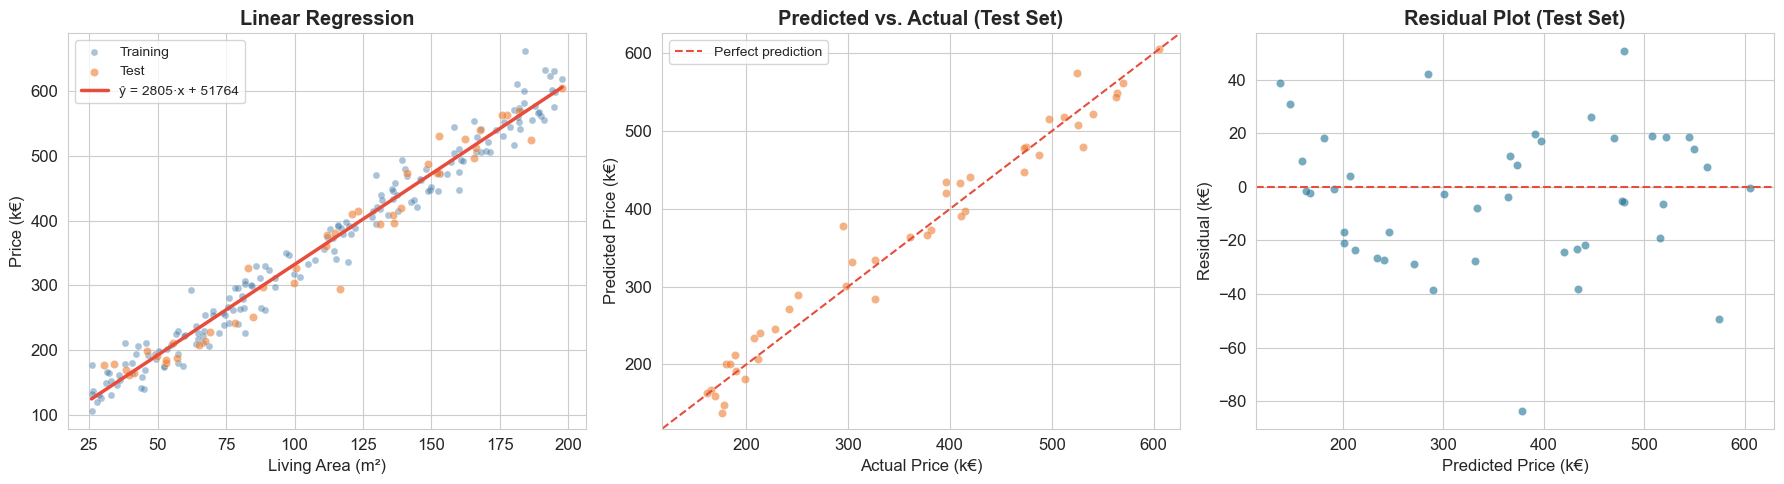

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- 1) Regression line ---
axes[0].scatter(X_train, y_train / 1000, alpha=0.4, s=25,
                color='#2E6B9E', label='Training', edgecolor='white', linewidth=0.3)
axes[0].scatter(X_test, y_test / 1000, alpha=0.6, s=35,
                color='#ED7D31', label='Test', edgecolor='white', linewidth=0.3)

# Plot the learned regression line
x_line = np.linspace(X['living_area_m2'].min(), X['living_area_m2'].max(), 100)
y_line = model.predict(x_line.reshape(-1, 1)) / 1000
axes[0].plot(x_line, y_line, color='#E74C3C', linewidth=2.5,
             label=f'ŷ = {w:.0f}·x + {b:.0f}')

axes[0].set_xlabel('Living Area (m²)')
axes[0].set_ylabel('Price (k€)')
axes[0].set_title('Linear Regression', fontweight='bold')
axes[0].legend(fontsize=10)

# --- 2) Predicted vs. Actual ---
axes[1].scatter(y_test / 1000, y_pred_test / 1000, alpha=0.6,
                s=35, color='#ED7D31', edgecolor='white', linewidth=0.3)
lim = [min(y_test.min(), y_pred_test.min()) / 1000 - 20,
       max(y_test.max(), y_pred_test.max()) / 1000 + 20]
axes[1].plot(lim, lim, '--', color='#E74C3C', linewidth=1.5, label='Perfect prediction')
axes[1].set_xlabel('Actual Price (k€)')
axes[1].set_ylabel('Predicted Price (k€)')
axes[1].set_title('Predicted vs. Actual (Test Set)', fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].set_xlim(lim)
axes[1].set_ylim(lim)

# --- 3) Residuals ---
residuals = (y_test - y_pred_test) / 1000
axes[2].scatter(y_pred_test / 1000, residuals, alpha=0.6,
                s=35, color='#1C7293', edgecolor='white', linewidth=0.3)
axes[2].axhline(y=0, color='#E74C3C', linewidth=1.5, linestyle='--')
axes[2].set_xlabel('Predicted Price (k€)')
axes[2].set_ylabel('Residual (k€)')
axes[2].set_title('Residual Plot (Test Set)', fontweight='bold')

plt.tight_layout()
plt.show()

---
## 7. Make New Predictions

In [9]:
# === PREDICTIONS FOR NEW HOUSES ===
new_houses = pd.DataFrame({
    'living_area_m2': [35, 55, 75, 100, 130, 160, 200]
})

new_houses['predicted_price_eur'] = model.predict(
    new_houses[['living_area_m2']]
).round(-2)

new_houses['price_formatted'] = new_houses['predicted_price_eur'].apply(
    lambda x: f'{x:,.0f} €'
)

print('=== Price Predictions for New Houses ===')
print(new_houses[['living_area_m2', 'price_formatted']].to_string(index=False))

=== Price Predictions for New Houses ===
 living_area_m2 price_formatted
             35       149,900 €
             55       206,000 €
             75       262,100 €
            100       332,300 €
            130       416,400 €
            160       500,500 €
            200       612,700 €


---
## 8. Summary

| Aspect | Result |
|--------|--------|
| **Model** | Linear Regression: ŷ = w · x + b |
| **Dataset** | 220 houses (176 train / 44 test) |
| **Learned price/m²** | ~2,800 €/m² |
| **Base price** | ~50,000 € |
| **R² (test)** | ~0.97 → model explains ~97% of the variance |

### Key Takeaway
A neural network is fundamentally an **extension** of this idea:  
Instead of a straight line, it learns arbitrarily complex functions — through multiple layers and nonlinear activations.